In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow import keras

(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
print(X_train_full.shape)
print(X_test.shape)
print(y_train_full.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


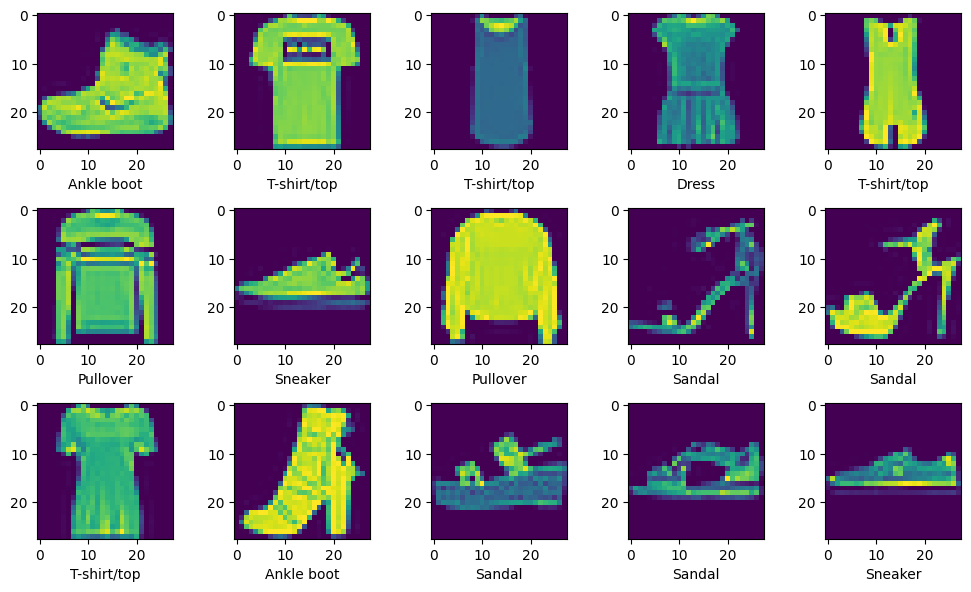

In [3]:
import matplotlib.pyplot as plt

fashion_category = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axs = plt.subplots(3, 5, figsize=(10, 6))
axs = axs.flatten()
for i in range(15):
    image = X_train_full[i]
    label = y_train_full[i]
    axs[i].imshow(image)
    axs[i].set_xlabel(fashion_category[label])
plt.tight_layout()  # This keeps titles from overlapping
# plt.subplots_adjust(hspace=1)
plt.show()


In [4]:
import numpy as np

NUM_CLASSES = len(fashion_category)

class_counts = np.bincount(y_train_full, minlength=NUM_CLASSES)
# print(class_counts)

for i, count in enumerate(class_counts):
    print(f"{fashion_category[i]}      ===> {count} image")


T-shirt/top      ===> 6000 image
Trouser      ===> 6000 image
Pullover      ===> 6000 image
Dress      ===> 6000 image
Coat      ===> 6000 image
Sandal      ===> 6000 image
Shirt      ===> 6000 image
Sneaker      ===> 6000 image
Bag      ===> 6000 image
Ankle boot      ===> 6000 image


In [5]:
# Split out a validation set using NumPy slicing
# Split the the train data into 80% for training and 20% for validation
X_train, X_valid = X_train_full[:48000], X_train_full[48000:]
y_train, y_valid = y_train_full[:48000], y_train_full[48000:]
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

# Normalize the image data (scale pixel integers down to 0.0 - 1.0 floats)
X_train = X_train / 255.0
X_valid = X_valid / 255.0
X_test = X_test / 255.0


(48000, 28, 28)
(12000, 28, 28)
(48000,)
(12000,)


In [6]:
# Initialize the NN model
OUTPUT_DIR = "aai_521_module_1_outputs"

BATCH_SIZE = 128
EPOCHS = 20

# Initialize the linear stack of layers
model = tf.keras.models.Sequential(
    [
        # 1. Flatten layer: Converts 28x28 images into a 1D array of 784 inputs
        tf.keras.layers.Flatten(input_shape=[28, 28]),
        # 2. Hidden layer: 128 nodes using the Rectified Linear Unit activation
        tf.keras.layers.Dense(BATCH_SIZE, activation='relu'),
        # 3. Output layer: 10 category (one for each class) using Softmax activation
        tf.keras.layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name="My_Fashion_MNIST_Model"
)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = model.fit(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid),
)



/Users/kiara/Documents/Amit-MS-Stuff/applied_computer_vision_for_AI_course/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8030 - loss: 0.5795 - val_accuracy: 0.8467 - val_loss: 0.4512
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8509 - loss: 0.4272 - val_accuracy: 0.8633 - val_loss: 0.3962
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8678 - loss: 0.3795 - val_accuracy: 0.8606 - val_loss: 0.3939
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8756 - loss: 0.3552 - val_accuracy: 0.8718 - val_loss: 0.3637
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8805 - loss: 0.3307 - val_accuracy: 0.8748 - val_loss: 0.3491
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8862 - loss: 0.3148 - val_accuracy: 0.8695 - val_loss: 0.3638
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8923 - loss: 0.3009 - val_accuracy: 0.8837 - val_loss: 0.3260
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8961 - loss: 0.2875 - val_accuracy: 0.

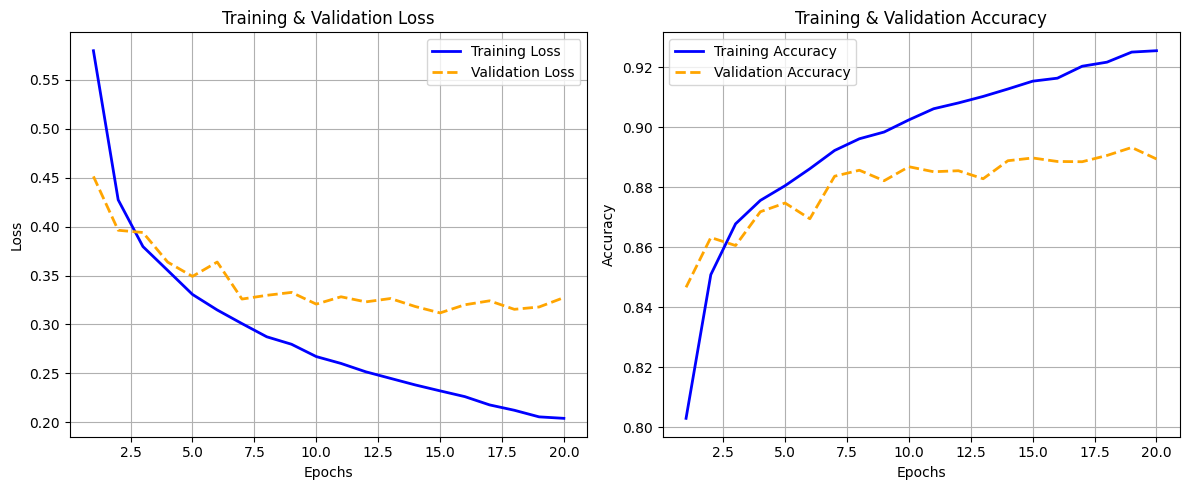

In [7]:
import matplotlib.pyplot as plt

# Extract metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Create a figure frame with two subplots side-by-side
plt.figure(figsize=(12, 5))

# Plot 1: Loss Curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', lw=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', lw=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid(True)

# Plot 2: Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', lw=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', lw=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training & Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



Suggestions to Resolve the Issue

To counter overfitting and force the neural network to generalize better, you can pitch these standard machine learning solutions in your assignment write-up:
• Introduce Dropout: Add a tf.keras.layers.Dropout(0.2) layer immediately after your hidden layer. This randomly turns off 20% of the nodes during each training step, preventing the network from relying too heavily on specific pathways or memorizing patterns.
• Apply Early Stopping: Instead of blindly running all 20 epochs, you can use a Keras callback (tf.keras.callbacks.EarlyStopping) to monitor the validation loss. The moment it detects that the validation loss has stopped improving for 3 or 4 epochs in a row, it automatically stops the training loop and keeps the best weights.

In [8]:
import pathlib
import tensorflow as tf

# 1. Define the official dataset archive download link
dataset_url = "http://download.tensorflow.org/example_images/flower_photos.tgz"

# 2. Let Keras download and extract (.tgz) the archive natively onto your local disk.
# This method manages folder paths safely and returns the exact location path string.
data_dir_path = tf.keras.utils.get_file(
    fname='flower_photos',
    origin=dataset_url,
    untar=True,
    cache_dir='.'  # Forces it to use the local directory instead of the hidden system path
)

# 3. Convert the downloaded path string into a Path object instance
data_dir = pathlib.Path(data_dir_path)

# 4. Search recursively for all JPG image file paths across the 5 subfolders
all_images = list(data_dir.glob('**/*.jpg'))

# 5. Output the calculations to your PyCharm console window
print(f"Dataset successfully downloaded to: {data_dir_path}")
print(f"Total number of images in the dataset: {len(all_images)}")


228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step
Dataset successfully downloaded to: ./datasets/flower_photos
Total number of images in the dataset: 7340


In [10]:
import pathlib

# Point to the local folder structure inside your project workspace
# Based on the previous step, Keras extracts it to './datasets/flower_photos'
data_dir_path = "datasets/flower_photos"
data_dir = pathlib.Path(data_dir_path)

total_number_of_images = 0

print("Reading subfolders from directory...\n")

# Iterate through all items inside the main directory
# We filter using item.is_dir() to make sure we only look at subfolders, ignoring any stray files
for item in data_dir.iterdir():
    if item.is_dir():
        # Get the name of the folder (e.g., 'daisy', 'roses')
        folder_name = item.name

        # Find all JPG images inside this specific subfolder
        # item.glob('*.jpg') looks only inside this single folder layer
        folder_images = list(item.glob('*.jpg'))
        image_count = len(folder_images)
        total_number_of_images += image_count

        # 3. Print the results for each subfolder to your PyCharm console
        print(f"Category Folder Name: '{folder_name}'")
        print(f"  -> Path: {item}")
        print(f"  -> Number of images: {image_count}\n")

print(f"Total Number of images in dataset: {total_number_of_images}\n")


Reading subfolders from directory...

Category Folder Name: 'roses'
  -> Path: datasets/flower_photos/roses
  -> Number of images: 641

Category Folder Name: 'sunflowers'
  -> Path: datasets/flower_photos/sunflowers
  -> Number of images: 699

Category Folder Name: 'daisy'
  -> Path: datasets/flower_photos/daisy
  -> Number of images: 633

Category Folder Name: 'flower_photos'
  -> Path: datasets/flower_photos/flower_photos
  -> Number of images: 0

Category Folder Name: 'dandelion'
  -> Path: datasets/flower_photos/dandelion
  -> Number of images: 898

Category Folder Name: 'tulips'
  -> Path: datasets/flower_photos/tulips
  -> Number of images: 799

Total Number of images in dataset: 3670



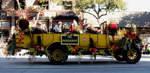

Folder Name: roses
Displaying image: 16209331331_343c899d38.jpg
Image Format: JPEG | Size: (150, 73) | Mode: RGB


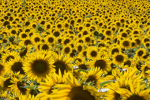

Folder Name: sunflowers
Displaying image: 6204049536_1ac4f09232_n.jpg
Image Format: JPEG | Size: (150, 100) | Mode: RGB


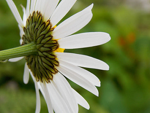

Folder Name: daisy
Displaying image: 14167534527_781ceb1b7a_n.jpg
Image Format: JPEG | Size: (150, 113) | Mode: RGB


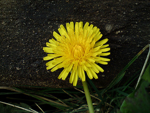

Folder Name: dandelion
Displaying image: 9965757055_ff01b5ee6f_n.jpg
Image Format: JPEG | Size: (150, 113) | Mode: RGB


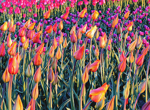

Folder Name: tulips
Displaying image: 5700466891_2bcb17fa68_n.jpg
Image Format: JPEG | Size: (150, 110) | Mode: RGB


In [17]:
from PIL import Image
from IPython.display import display

data_dir_path = "datasets/flower_photos"
data_dir = pathlib.Path(data_dir_path)

for item in data_dir.iterdir():
    if item.is_dir():
        folder_name = item.name
        folder_images = list(item.glob('*.jpg'))
        first_image_from_folder = folder_images[0]
        image = Image.open(first_image_from_folder)
        image.thumbnail((150, 150))
        display(image)
        # Print file details to the PyCharm console
        print(f"Folder Name: {folder_name}")
        print(f"Displaying image: {first_image_from_folder.name}")
        print(f"Image Format: {image.format} | Size: {image.size} | Mode: {image.mode}")

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.


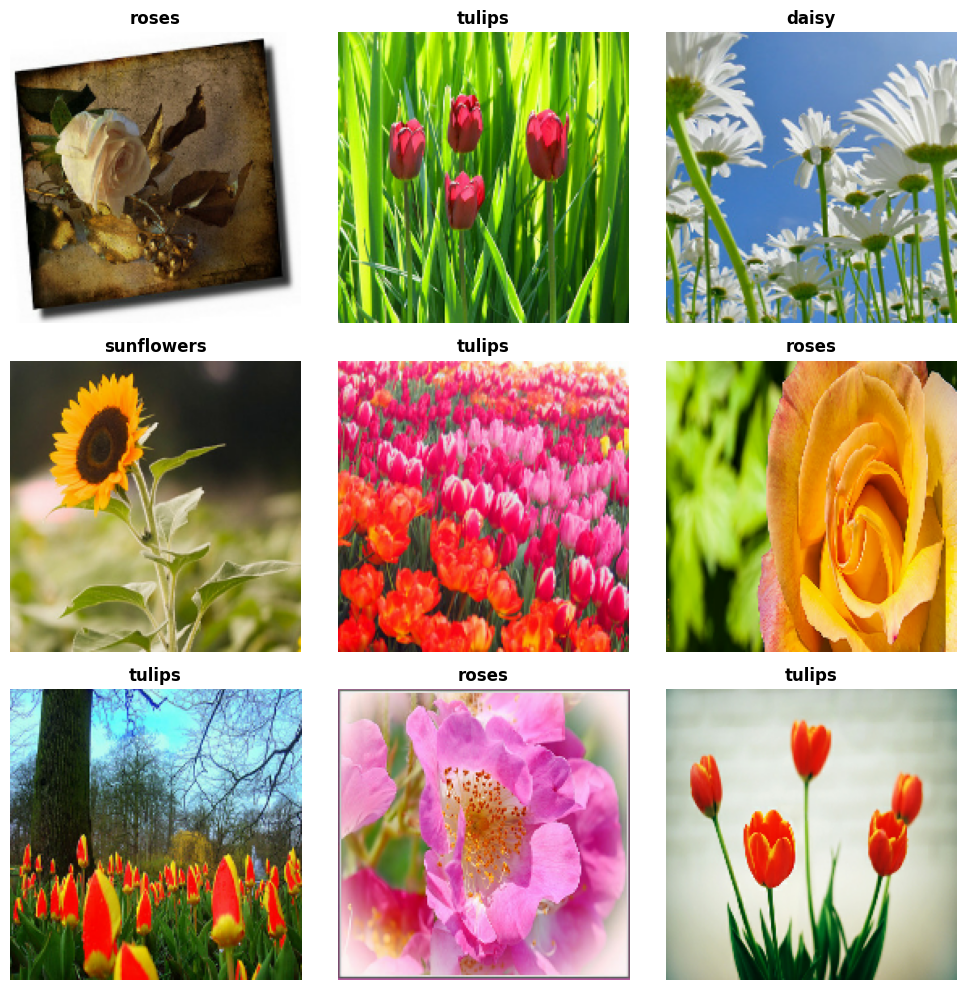

In [18]:
import tensorflow as tf
import matplotlib.pyplot as plt

data_dir_path = "datasets/flower_photos"
IMAGE_BATCH_SIZE = 50

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_path,
    validation_split=0.2,       # Allocates exactly 20% of the images for validation
    subset="training",        # Dictates that this loader object reads the validation slice
    seed=123,                   # Ensures a matching shuffle profile if run alongside training data
    image_size=(180, 180),      # Standardizes all varying image dimensions to 180x180 pixels
    batch_size=IMAGE_BATCH_SIZE # Groups the inputs into chunks of 32 images per calculation step
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_path,
    validation_split=0.2,       # Must match the split percentage above
    subset="validation",        # Defines this specific object as the validation data
    seed=123,                   # Must match the exact same seed to prevent image overlap
    image_size=(180, 180),      # Must match the exact same target size
    batch_size=32
)


# Extract the string names of the 5 categories
class_names = train_ds.class_names

# Pull exactly 1 randomized batch from the dataset pipeline
for images_batch, labels_batch in train_ds.take(1):

    # Initialize a 3x3 plotting grid structure
    plt.figure(figsize=(10, 10))

    for i in range(9):
        plt.subplot(3, 3, i + 1)

        # Convert the tensor image array to integers (0-255) for Matplotlib rendering
        # Keras loads image pixels as float32 matrices by default
        img_array = images_batch[i].numpy().astype("uint8")
        plt.imshow(img_array)

        # Look up the integer label in our class_names list to get the text string
        label_text = class_names[labels_batch[i]]
        plt.title(label_text, fontsize=12, fontweight='bold')

        # Turn off grid borders and coordinate numbers
        plt.axis("off")

    plt.tight_layout()
    plt.show()



In [19]:
import tensorflow as tf
from tensorflow.keras import layers

# Initialize the new flower model
flower_model = tf.keras.models.Sequential([
    # --- OPTION A PREPROCESSING LAYERS (Run automatically on the fly) ---
    layers.Input(shape=(180, 180, 3)),                # Define the flower image dimensions
    layers.Rescaling(1.0 / 255.0),                     # Rescale pixel values (0-255 -> 0-1)
    layers.RandomShear(x_factor=0.2, y_factor=0.0),    # 'shear_factor' to 'x_factor' for a 20% horizontal shear
    layers.RandomZoom(height_factor=(-0.2, 0.2)),      # Zoom 20%
    layers.RandomFlip(mode="horizontal"),              # Horizontal flip

    # --- CORE NN ARCHITECTURE LAYERS ---
    # Because images are large (180x180x3 = 97,200 inputs), we add a Conv2D layer
    # to find visual features before flattening.
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Flatten the extracted feature maps into a 1D vector
    layers.Flatten(),

    # Hidden Layer (as requested in your early rules, e.g., 128 nodes)
    layers.Dense(128, activation='relu'),

    # Output Layer (MUST be 5 for the flower classes!)
    layers.Dense(5, activation='softmax')
], name="My_Flower_Classification_Model")

# Compile with the exact same structured loss settings
flower_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fit using your new tf.data validation pipelines directly
# (No need to pass batch_size here because the pipeline handles it automatically)
history = flower_model.fit(
    train_ds,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=val_ds
)



Epoch 1/20


/Users/kiara/Documents/Amit-MS-Stuff/applied_computer_vision_for_AI_course/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


59/59 ━━━━━━━━━━━━━━━━━━━━ 28s 455ms/step - accuracy: 0.3610 - loss: 4.7518 - val_accuracy: 0.5095 - val_loss: 1.2028
Epoch 2/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 24s 406ms/step - accuracy: 0.5272 - loss: 1.1506 - val_accuracy: 0.5681 - val_loss: 1.1459
Epoch 3/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 29s 496ms/step - accuracy: 0.6015 - loss: 1.0562 - val_accuracy: 0.5967 - val_loss: 1.0491
Epoch 4/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 26s 439ms/step - accuracy: 0.6291 - loss: 0.9969 - val_accuracy: 0.5899 - val_loss: 1.0549
Epoch 5/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 26s 428ms/step - accuracy: 0.6393 - loss: 0.9639 - val_accuracy: 0.6199 - val_loss: 1.0556
Epoch 6/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 27s 455ms/step - accuracy: 0.6516 - loss: 0.9224 - val_accuracy: 0.6035 - val_loss: 1.0073
Epoch 7/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 26s 433ms/step - accuracy: 0.6853 - loss: 0.8796 - val_accuracy: 0.6376 - val_loss: 0.9554
Epoch 8/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 29s 491ms/step - accuracy: 0.6792 - loss: 0.8494 - val_accuracy: 0.654

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step


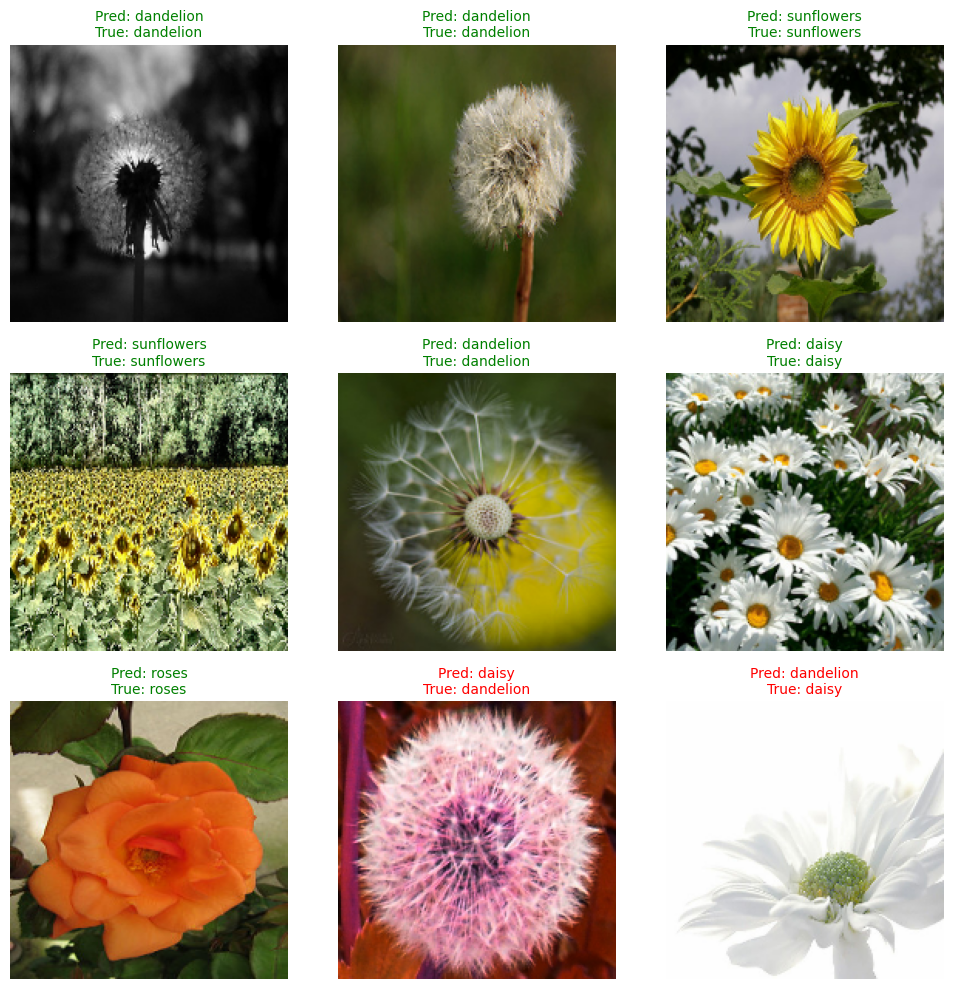

In [20]:
# Predict a Batch of Validation Images
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab exactly one batch of 32 images from your validation pipeline
images_batch, labels_batch = next(iter(val_ds))

# 2. Generate predictions for the entire batch all at once
predictions = flower_model.predict(images_batch)
class_names = train_ds.class_names

# 3. Setup a 3x3 grid window to visualize 9 images from this batch
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)

    # Render the image array
    plt.imshow(images_batch[i].numpy().astype("uint8"))

    # Find the model's top predicted label index and compare it to the true label
    predicted_label = class_names[np.argmax(predictions[i])]
    true_label = class_names[labels_batch[i]]

    # Change the text color to green if the model is right, red if it's wrong!
    color = 'green' if predicted_label == true_label else 'red'

    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Testing File: 3517492544_0fd3ed6a66_m.jpg
True Category: 'dandelion' | Predicted: 'dandelion' (34.15%)


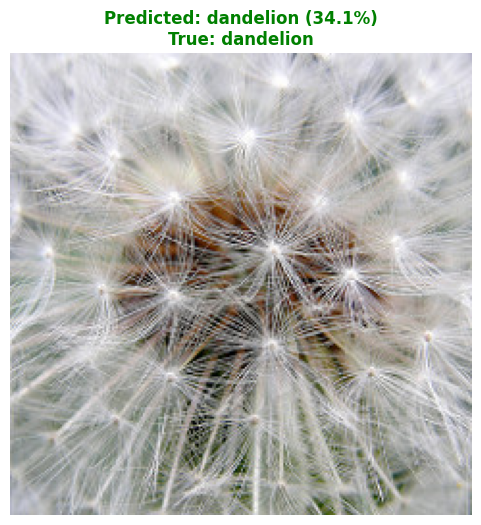

In [29]:
# Test on a Single Image from the Web

import random
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import pathlib

# 1. Point to your local dataset directory inside your project folder
data_dir = pathlib.Path("datasets/flower_photos")

# 2. Grab the local path list of all JPG image files available on your disk
all_local_images = list(data_dir.glob('**/*.jpg'))

if all_local_images:
    # 3. Pick one image file path completely at random from your folder structure
    random_image_path = random.choice(all_local_images)

    # 4. Process the image for the model (Resized to 180x180 so the network can read it)
    model_img = tf.keras.utils.load_img(
        random_image_path, target_size=(180, 180)
    )
    img_array = tf.keras.utils.img_to_array(model_img)
    img_array = tf.expand_dims(img_array, 0)

    # 5. Load the completely ORIGINAL image footprint for visual display
    # Leaving out target_size keeps the full original width, height, and resolution
    display_img = tf.keras.utils.load_img(random_image_path)

    # 6. Run the prediction pipeline
    predictions = flower_model.predict(img_array)
    score = tf.nn.softmax(predictions)

    # 7. Extract class names and labels
    class_names = train_ds.class_names
    predicted_class = class_names[np.argmax(score)]
    true_class = random_image_path.parent.name
    confidence = 100 * np.max(score)

    print(f"Testing File: {random_image_path.name}")
    print(f"True Category: '{true_class}' | Predicted: '{predicted_class}' ({confidence:.2f}%)")

    # 8. DISPLAY THE ORIGINAL VISUAL IMAGE
    plt.figure(figsize=(6, 6))

    # Render the raw, untouched original image object
    plt.imshow(display_img)

    # Color code the header: Green if correct, Red if incorrect
    title_color = 'green' if predicted_class == true_class else 'red'

    # Place text styling on top of the image display frame
    plt.title(
        f"Predicted: {predicted_class} ({confidence:.1f}%)\nTrue: {true_class}",
        color=title_color,
        fontsize=12,
        fontweight='bold'
    )

    plt.axis("off")  # Remove grid lines and axes numbers
    plt.show()       # Open the native graphic pop-up window

else:
    print("No images found in your local project directory folder structure.")


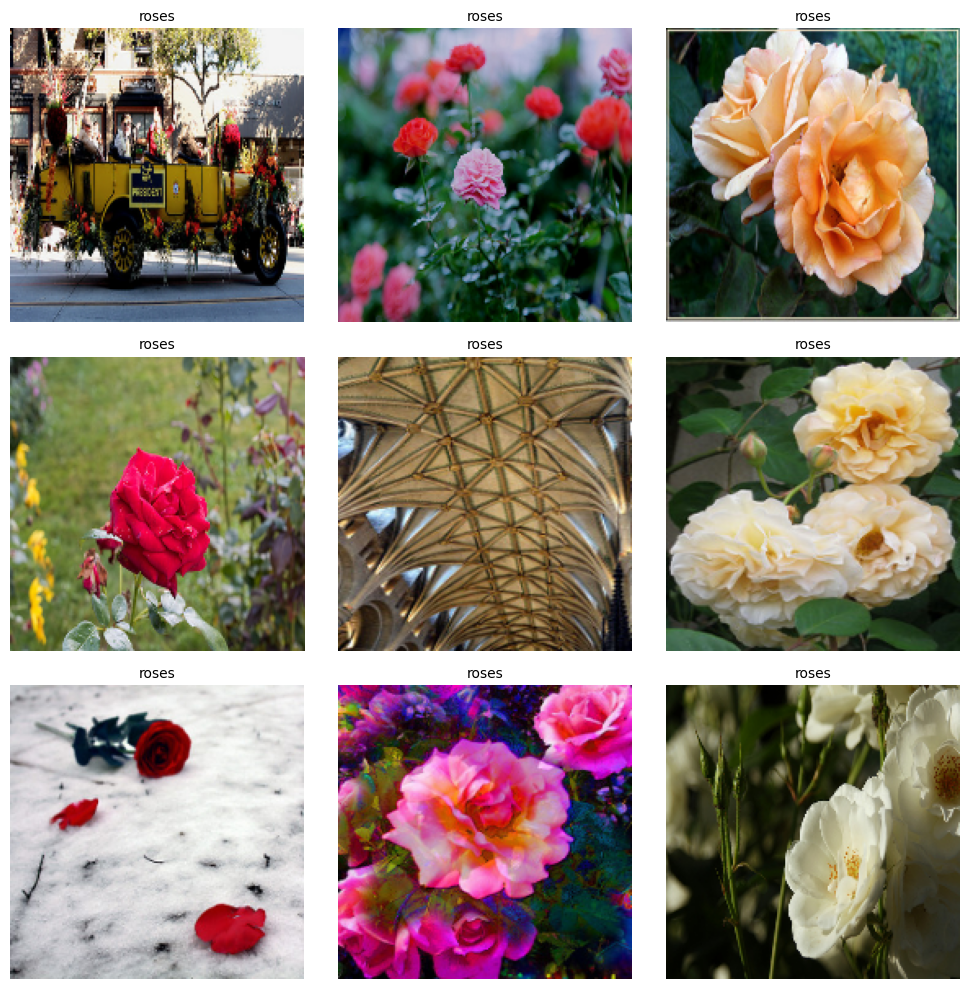

In [1]:
import pathlib
import cv2
import matplotlib.pyplot as plt

data_dir = pathlib.Path("datasets/flower_photos")
all_local_images = list(data_dir.glob('**/*.jpg'))

plt.figure(figsize=(10, 10))

for i in range(min(9, len(all_local_images))):
    image_path = all_local_images[i]

    # Load -> Resize -> Fix Color to Normal
    img_bgr = cv2.imread(str(image_path))
    img_resized = cv2.resize(img_bgr, (180, 180))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)  # Part 3b fix

    # Plot inside a single 3x3 graphic layout
    plt.subplot(3, 3, i + 1)
    plt.imshow(img_rgb)  # Matplotlib renders normal RGB perfectly
    plt.title(image_path.parent.name, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()
